# NLP Assignment 1 (40% of grade): Sentiment Analysis from Tweets

This coursework will involve you implementing functions for a text classifier, which you will train to identify the **sentiment expressed in a text** in a dataset of approx. 27,000 entries, which will be split into a 80%/20% training/test split. 

In this template you are given the basis for that implementation, though some of the functions are missing, which you have to fill in.

Follow the instructions file **NLP_Assignment_1_Instructions.pdf** for details of each question - the outline of what needs to be achieved for each question is as below.

You must submit all **ipython notebooks and extra resources you need to run the code if you've added them** in the code submission, and a **2 page report (pdf)** in the report submission on QMPlus where you report your methods and findings according to the instructions file for each question. **NB:** this report is strictly limited to 2 pages, and any additional pages will not be considered during marking. You are expected to write concisely within the 2 pages, and any additional texts beyond this will not be considered as part of the report.

In [1]:
pip install nltk

Note: you may need to restart the kernel to use updated packages.


In [2]:
import csv                               # csv reader
from sklearn.svm import LinearSVC
from nltk.classify import SklearnClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_recall_fscore_support # to report on precision and recall
import numpy as np
from collections import Counter

In [3]:
def load_data(path):
    """Load data from a tab-separated file and append it to raw_data."""
    with open(path) as f:
        reader = csv.reader(f, delimiter='\t')
        for line in reader:
            # skip data that are corrupted
            if len(line) < 3:
                continue
            (label, text) = parse_data_line(line)
            raw_data.append((text, label))

def split_and_preprocess_data(percentage):
    """Split the data between train_data and test_data according to the percentage
    and performs the preprocessing."""
    num_samples = len(raw_data)
    num_training_samples = int((percentage * num_samples))
    for (text, label) in raw_data[:num_training_samples]:
        train_data.append((to_feature_vector(pre_process(text)),label))
    for (text, label) in raw_data[num_training_samples:]:
        test_data.append((to_feature_vector(pre_process(text)),label))
        
def parse_data_line(data_line):
    """Return a tuple of the label as just FAKE or REAL and the statement"""
    return (data_line[1], data_line[2])

import re, nltk
from nltk.corpus import stopwords

nltk.download('stopwords', quiet=True)

#REGEX
URL_RE      = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE  = re.compile(r"@\w+")
HASHTAG_RE  = re.compile(r"#(\w+)")
#ELONG_RE    = re.compile(r"(.)\1{2,}")  # e.g. sooo → soo

#LEXICAL RESOURCES
NEGATORS    = {"not", "no", "never", "n't"}
INTENSIFIERS= {"very", "so", "too", "really", "extremely"}
STOPWORDS   = set(stopwords.words("english")) - NEGATORS - INTENSIFIERS

# Lemmatization setting ip 
#import nltk
#from nltk.stem import WordNetLemmatizer
#from nltk import pos_tag
#from nltk.corpus import wordnet

#nltk.download('wordnet', quiet=True)
#nltk.download('averaged_perceptron_tagger', quiet=True)

#LEMM = WordNetLemmatizer()
#import emoji

def get_wordnet_pos(tag):
    """Map POS tags (e.g. NN, VB) to WordNet POS tags for lemmatizer."""
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    return wordnet.NOUN
    
def pre_process(text):
    """Return a list of tokens"""
    text = text.lower()
    text = URL_RE.sub(" ", text)
    text = MENTION_RE.sub(" ", text)
    text = HASHTAG_RE.sub(lambda m: f"{m.group(1)} HASHTAG_{m.group(1)}", text)
#    text = ELONG_RE.sub(r"\1\1", text)
#    import emoji
#    text = ''.join(
#        ch if ch.isalpha() or ch in "!?'" or ch in emoji.EMOJI_DATA else ' '
#        for ch in text
#    )
    text = re.sub(r"[^a-z!?'\s]", " ", text)
    text = re.sub(r"([!?])\1+", r"\1", text)  # !!! → !
    toks = text.split()
    toks = [t for t in toks if len(t) > 1 and t not in STOPWORDS]
    # Negation window: mark next 3 words after negator
    #out = []
    #for i, t in enumerate(toks):
     #   if t in NEGATORS:
     #       out.append(t)
            #for j in range(1, 4):
             #   if i+j < len(toks):
              #      toks[i+j] = toks[i+j] + "_NEG"
      #  else:
      #      out.append(t)
    #return out
    #POS tagging + lemmatisation
    #tagged = pos_tag(toks)
    #toks = [LEMM.lemmatize(w, get_wordnet_pos(p)) for (w, p) in tagged]
     #add bigrams & trigrams
    
    ngram_tokens = []
    for n in (2, 3):
        ngram_tokens += ["__".join(toks[i:i+n]) for i in range(len(toks) - n + 1)]
        
    # capture emojis separately before lowercasing
#    emoji_chars = [ch for ch in text if ch in emoji.EMOJI_DATA]
    
     # append emojis to tokens so they are part of the feature space
#    if emoji_chars:
#        toks.extend(emoji_chars)

    # return unigrams + n-grams
    return toks + ngram_tokens
   

In [4]:
# test
text = "RT @colonelkickhead: Another bloody instant restaurant week?!?! Seriously! They just jumped the shark riding two other sharks powered by sh…"
pre_process(text)

['rt',
 'another',
 'bloody',
 'instant',
 'restaurant',
 'week?!?!',
 'seriously!',
 'jumped',
 'shark',
 'riding',
 'two',
 'sharks',
 'powered',
 'sh',
 'rt__another',
 'another__bloody',
 'bloody__instant',
 'instant__restaurant',
 'restaurant__week?!?!',
 'week?!?!__seriously!',
 'seriously!__jumped',
 'jumped__shark',
 'shark__riding',
 'riding__two',
 'two__sharks',
 'sharks__powered',
 'powered__sh',
 'rt__another__bloody',
 'another__bloody__instant',
 'bloody__instant__restaurant',
 'instant__restaurant__week?!?!',
 'restaurant__week?!?!__seriously!',
 'week?!?!__seriously!__jumped',
 'seriously!__jumped__shark',
 'jumped__shark__riding',
 'shark__riding__two',
 'riding__two__sharks',
 'two__sharks__powered',
 'sharks__powered__sh']

# Question 4: Optimised Feature Extraction 

In [5]:
global_feature_dict = {} # A global dictionary of features

from nltk.sentiment.vader import SentimentIntensityAnalyzer
sid = SentimentIntensityAnalyzer()

from nltk.corpus import opinion_lexicon
import nltk
nltk.download('opinion_lexicon', quiet=True)

POS_LEX = set(opinion_lexicon.positive())
NEG_LEX = set(opinion_lexicon.negative())

from nltk import pos_tag


def to_feature_vector(tokens):
    # count token frq and convert counter objects into a plain python dict 
    global global_feature_dict
     # count how many times a token appears
    feature_dict = dict(Counter(tokens))
    
    feature_dict["VADER_SCORE"] = sid.polarity_scores(" ".join(tokens))["compound"]
        
    feature_dict["LEX_POS_COUNT"] = sum(t in POS_LEX for t in tokens)
    feature_dict["LEX_NEG_COUNT"] = sum(t in NEG_LEX for t in tokens)
    feature_dict["LEX_POLARITY"] = feature_dict["LEX_POS_COUNT"] - feature_dict["LEX_NEG_COUNT"]

    pos = feature_dict.get("LEX_POS_COUNT", 0)
    neg = feature_dict.get("LEX_NEG_COUNT", 0)
    total = pos + neg if (pos + neg) > 0 else 1
    feature_dict["POLARITY_RATIO"] = (pos - neg) / total
    
    
    feature_dict["TOKEN_COUNT"] = len(tokens)
    feature_dict["AVG_TOKEN_LEN"] = np.mean([len(t) for t in tokens]) if tokens else 0
    feature_dict["EXCLAM_COUNT"] = sum("!" in t for t in tokens)
    feature_dict["QUEST_COUNT"] = sum("?" in t for t in tokens)
    
      #emoji sentiment score
#    emoji_polarity = {
#        "😊": 0.8, "😂": 0.8, "❤️": 1.0, 
#        "👍": 0.5, "😭": -0.9, "😡": -0.8,
#        "👎": -0.5, "💔": -1.0
#    }
#    emoji_score = sum(emoji_polarity.get(ch, 0) for ch in tokens if ch in emoji.EMOJI_DATA)
#    feature_dict["EMOJI_SCORE"] = float(emoji_score)
        #CHARACTER N-GRAMS
#    for t in tokens:
#        for k in [3, 4, 5]:  # lengths of n-grams
#            for i in range(len(t) - k + 1):
#                key = f"C{k}_{t[i:i+k]}"
#                feature_dict[key] = feature_dict.get(key, 0) + 1
    # records tokens in the global lib
    for token in feature_dict:
        global_feature_dict[token] = global_feature_dict.get(token, 0) + 1
    for t in tokens:
        if t in INTENSIFIERS:
            feature_dict[t] = feature_dict.get(t, 0) + 2
            
        # k smoothing 
    k = 0.3  # small bias
    for token in feature_dict:
        feature_dict[token] = feature_dict[token] + k    



#    feature_dict["HASHTAG_COUNT"] = sum("HASHTAG_" in t for t in tokens)
#    feature_dict["INTENSIFIER_COUNT"] = sum(t in INTENSIFIERS for t in tokens)
    
# pos ratios took too long to load
#        feature_dict = dict(Counter(tokens))
#        tagged = pos_tag(tokens)
#        pos_counts = Counter(tag[1] for tag in tagged)
#        total = len(tokens) or 1
    
#        feature_dict["RATIO_ADJ"] = pos_counts["JJ"] / total
#        feature_dict["RATIO_ADV"] = pos_counts["RB"] / total
#        feature_dict["RATIO_VERB"] = (pos_counts["VB"] + pos_counts["VBD"] + pos_counts["VBG"]) / total
#        feature_dict["RATIO_NOUN"] = (pos_counts["NN"] + pos_counts["NNS"]) / total

#    if any(ch.isupper() for ch in " ".join(tokens)):
#        vader_boost = sid.polarity_scores(" ".join(tokens))["compound"]
#        feature_dict["SHOUT_INTENSITY"] = vader_boost * 1.5
#    else:
#        feature_dict["SHOUT_INTENSITY"] = 0

        # --- Log scaling ---
    for token in feature_dict:
        val = feature_dict[token]
        if val < 0:  # shifts negatives upward so log1p is valid
            val = 0
        feature_dict[token] = np.log1p(val)
        
    return feature_dict
#tokens = pre_process("This is amazing 😍😍!!! I didnt like this at all 😡")
#features = to_feature_vector(tokens)
#print("EMOJI_SCORE:", features.get("EMOJI_SCORE"))



In [6]:
# TRAINING AND VALIDATING OUR CLASSIFIER

def train_classifier(data):
    print("Training Classifier...")
    from sklearn.ensemble import VotingClassifier
    from sklearn.linear_model import LogisticRegression
    from sklearn.svm import LinearSVC
    
#    pipeline = Pipeline([
#        ('vote', VotingClassifier(estimators=[
#            ('svc', LinearSVC(C=0.5)),
#            ('lr', LogisticRegression(solver='liblinear'))
#        ], voting='hard'))
#    ])
    pipeline =  Pipeline([('svc', LinearSVC(C=0.5, max_iter=10000, tol=1e-3, class_weight='balanced'))])

#    from sklearn.linear_model import PassiveAggressiveClassifier
#    pipeline = Pipeline([('pac', PassiveAggressiveClassifier(C=0.5))])
    
#    from sklearn.linear_model import LogisticRegression
#    pipeline = Pipeline([('lr', LogisticRegression(solver='liblinear'))])

#    pipeline = Pipeline([
#        ('svc', LinearSVC(max_iter=10000, tol=1e-3, class_weight='balanced'))
#    ])
    
    # pipeline =  Pipeline([('svc', LinearSVC(max_iter=10000, tol=1e-3))])
    return SklearnClassifier(pipeline).train(data)

# TRAINING AND VALIDATING OUR CLASSIFIER
#from sklearn.linear_model import SGDClassifier
#def train_classifier(data):
#    print("Training Classifier...")
 #   pipeline = Pipeline([
  #      ('sgd', SGDClassifier(
   #         loss="log_loss",
    #        penalty="l2",
     #       alpha=1e-5,
      #      max_iter=20000,
       #     tol=1e-4,
        #    random_state=42,
         #   class_weight='balanced'
#        ))
#    ])
#    return SklearnClassifier(pipeline).train(data)
    
#    pipeline =  Pipeline([('svc', LinearSVC())])
    
#    pipeline = Pipeline([
#        ('svc', LinearSVC(max_iter=10000, tol=1e-3, class_weight='balanced'))
#    ])
    
    # pipeline =  Pipeline([('svc', LinearSVC(max_iter=10000, tol=1e-3))])
#    return SklearnClassifier(pipeline).train(data) 

# Question 4: Optimised Cross-validation 

In [7]:
from sklearn.metrics import precision_recall_fscore_support, accuracy_score
import numpy as np

def cross_validate(dataset, folds=10):
    fold_size = int(len(dataset) / folds) + 1
    scores = []

    for i in range(0, len(dataset), fold_size):
        print("fold", i // fold_size + 1)
        test = dataset[i:i + fold_size]
        train = dataset[:i] + dataset[i + fold_size:]
        clf = train_classifier(train)
        preds = predict_labels([x for x, _ in test], clf)
        y = [y for _, y in test]
        p, r, f, _ = precision_recall_fscore_support(y, preds, average='binary', pos_label='positive')
        scores.append((p, r, f, accuracy_score(y, preds)))

    avg = np.mean(scores, axis=0)
    res = {'precision': avg[0], 'recall': avg[1], 'f1': avg[2], 'accuracy': avg[3]}
    print("cross validation complete\n", res)
    return res

In [8]:
# PREDICTING LABELS GIVEN A CLASSIFIER

def predict_labels(samples, classifier):
    """Assuming preprocessed samples, return their predicted labels from the classifier model."""
    return classifier.classify_many(samples)

def predict_label_from_raw(sample, classifier):
    """Assuming raw text, return its predicted label from the classifier model."""
    return classifier.classify(to_feature_vector(preProcess(reviewSample)))

In [9]:
# MAIN

# loading reviews
# initialize global lists that will be appended to by the methods below
raw_data = []          # the filtered data from the dataset file
train_data = []        # the pre-processed training data as a percentage of the total dataset
test_data = []         # the pre-processed test data as a percentage of the total dataset


# references to the data files
data_file_path = 'sentiment-dataset.tsv'

# Do the actual stuff (i.e. call the functions we've made)
# We parse the dataset and put it in a raw data list
print("Now %d rawData, %d trainData, %d testData" % (len(raw_data), len(train_data), len(test_data)),
      "Preparing the dataset...",sep='\n')

load_data(data_file_path) 

# We split the raw dataset into a set of training data and a set of test data (80/20)
# You do the cross validation on the 80% (training data)
# We print the number of training samples and the number of features before the split
print("Now %d rawData, %d trainData, %d testData" % (len(raw_data), len(train_data), len(test_data)),
      "Preparing training and test data...",sep='\n')

split_and_preprocess_data(0.8)

# We print the number of training samples and the number of features after the split
print("After split, %d rawData, %d trainData, %d testData" % (len(raw_data), len(train_data), len(test_data)),
      "Training Samples: ", len(train_data), "Features: ", len(global_feature_dict), sep='\n')


Now 0 rawData, 0 trainData, 0 testData
Preparing the dataset...
Now 33540 rawData, 0 trainData, 0 testData
Preparing training and test data...
After split, 33540 rawData, 26832 trainData, 6708 testData
Training Samples: 
26832
Features: 
593064


In [10]:
cross_validate(train_data, 10)  # will work and output overall performance of p, r, f-score when cv implemented

fold 1
Training Classifier...
fold 2
Training Classifier...
fold 3
Training Classifier...
fold 4
Training Classifier...
fold 5
Training Classifier...
fold 6
Training Classifier...
fold 7
Training Classifier...
fold 8
Training Classifier...
fold 9
Training Classifier...
fold 10
Training Classifier...
cross validation complete
 {'precision': 0.8913398069452928, 'recall': 0.9178040965126364, 'f1': 0.9043297224037705, 'accuracy': 0.8742565699633994}


{'precision': 0.8913398069452928,
 'recall': 0.9178040965126364,
 'f1': 0.9043297224037705,
 'accuracy': 0.8742565699633994}

# Question 4: Error Analysis

In [11]:
from sklearn import metrics
import matplotlib.pyplot as plt
# a function to make the confusion matrix readable and pretty
def confusion_matrix_heatmap(y_test, preds, labels):
    """Function to plot a confusion matrix"""
    # pass labels to the confusion matrix function to ensure right order
    # cm = metrics.confusion_matrix(y_test, preds, labels)
    cm = metrics.confusion_matrix(y_test, preds, labels=labels)
    fig = plt.figure(figsize=(10,10))
    ax = fig.add_subplot(111)
    cax = ax.matshow(cm)
    plt.title('Confusion matrix of the classifier')
    fig.colorbar(cax)
    ax.set_xticks(np.arange(len(labels)))
    ax.set_yticks(np.arange(len(labels)))
    ax.set_xticklabels( labels, rotation=45)
    ax.set_yticklabels( labels)

    for i in range(len(cm)):
        for j in range(len(cm)):
            text = ax.text(j, i, cm[i, j],
                           ha="center", va="center", color="w")

    plt.xlabel('Predicted')
    plt.ylabel('True')
    
    # fix for mpl bug that cuts off top/bottom of seaborn viz:
    b, t = plt.ylim() # discover the values for bottom and top
    b += 0.5 # Add 0.5 to the bottom
    t -= 0.5 # Subtract 0.5 from the top
    plt.ylim(b, t) # update the ylim(bottom, top) values
    plt.show() # ta-da!
    plt.show()

Training Classifier...


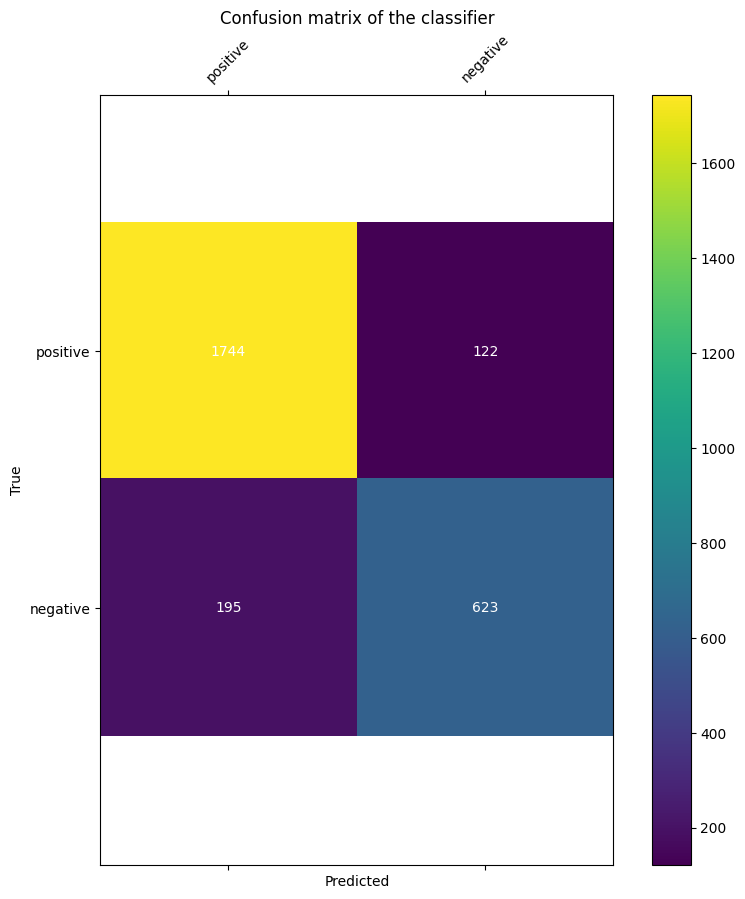

True Positives (TP): 1744
False Negatives (FN): 122
False Positives (FP): 195
True Negatives (TN): 623

F1 score on this fold: 0.9167
False Positives: 7.27% of all predictions
False Negatives: 4.55% of all predictions

 Falsely classified tweets:

False Positive #1: good news tonight fidel castro assumed room temperature need brother maduro follow quickly good__news news__tonight ...

False Negative #1: heard said nd snoop dogg represents extra gangsterishness else explain particular redundancy? heard__said said__nd nd__snoop ...

False Negative #2: shake bon rickymartin onewor shake__bon bon__bon bon__rickymartin rickymartin__rickymartin rickymartin__onewor onewor__onewor shake__bon__bon bon__bon__rickymartin bon__rickymartin__rickymartin rickymartin__rickymartin__onewor rickymartin__onewor__onewor ...

False Positive #2: italian police stopped california rapper snoop dogg friday prepared board private plane bound italian__police police__stopped ...

False Positive #3: seriously may p

In [12]:
from sklearn.metrics import confusion_matrix, f1_score

# Select the first fold for analysis
k = int(len(train_data) / 10) + 1
clf = train_classifier(train_data[k:])  # train on folds 2–10
preds = predict_labels([x for x, _ in train_data[:k]], clf)
true = [y for _, y in train_data[:k]]

confusion_matrix_heatmap(true, preds, ["positive", "negative"])

# Compute confusion matrix values
cm = confusion_matrix(true, preds, labels=["positive", "negative"])
tp, fn, fp, tn = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]
total = tp + tn + fp + fn
print(f"True Positives (TP): {tp}")
print(f"False Negatives (FN): {fn}")
print(f"False Positives (FP): {fp}")
print(f"True Negatives (TN): {tn}")

fp_percent = (fp / total) * 100
fn_percent = (fn / total) * 100

# F1 score for this fold
f1 = f1_score(true, preds, pos_label="positive")
print(f"\nF1 score on this fold: {f1:.4f}")
print(f"False Positives: {fp_percent:.2f}% of all predictions")
print(f"False Negatives: {fn_percent:.2f}% of all predictions")

# --- Example wrong tweets---
fp_count, fn_count = 0, 0
print("\n Falsely classified tweets:")
for (x, y), p in zip(train_data[:k], preds):
    if p == "positive" and y == "negative" and fp_count < 3:
        fp_count += 1
        print(f"\nFalse Positive #{fp_count}: {' '.join(list(x.keys())[:15])} ...")
    elif p == "negative" and y == "positive" and fn_count < 3:
        fn_count += 1
        print(f"\nFalse Negative #{fn_count}: {' '.join(list(x.keys())[:15])} ...")
    if fp_count >= 3 and fn_count >= 3:
        break

# Question 4: Optimising pre-processing and feature extraction (50 marks)

**Note:** it is advisable to implement question 4 in a separate notebook where you further develop the pre-processing and feature extraction functions you implemented above.

In [13]:
# Finally, check the accuracy of your classifier by training on all the traning data
# and testing on the test set
# Will only work once all functions are complete
functions_complete = True  # set to True once you're happy with your methods for cross val
if functions_complete:
    print(test_data[0])   # have a look at the first test data instance
    classifier = train_classifier(train_data)  # train the classifier
    test_true = [t[1] for t in test_data]   # get the ground-truth labels from the data
    test_pred = predict_labels([x[0] for x in test_data], classifier)  # classify the test data to get predicted labels
    final_scores = precision_recall_fscore_support(test_true, test_pred, average='weighted') # evaluate
    print("Done training!")
    print("Precision: %f\nRecall: %f\nF Score:%f" % final_scores[:3])

({'tomorrow': 0.832909122935104, 'release': 0.832909122935104, 'th': 0.832909122935104, 'episode': 0.832909122935104, 'hsonair': 1.1939224684724346, 'profiling': 0.832909122935104, 'very': 1.4586150226995167, 'talk': 0.832909122935104, 'storytelling': 0.832909122935104, 'beyonce!': 0.832909122935104, 'tomorrow__release': 0.832909122935104, 'release__th': 0.832909122935104, 'th__episode': 0.832909122935104, 'episode__hsonair': 0.832909122935104, 'hsonair__hsonair': 0.832909122935104, 'hsonair__profiling': 0.832909122935104, 'profiling__very': 0.832909122935104, 'very__talk': 0.832909122935104, 'talk__storytelling': 0.832909122935104, 'storytelling__beyonce!': 0.832909122935104, 'tomorrow__release__th': 0.832909122935104, 'release__th__episode': 0.832909122935104, 'th__episode__hsonair': 0.832909122935104, 'episode__hsonair__hsonair': 0.832909122935104, 'hsonair__hsonair__profiling': 0.832909122935104, 'hsonair__profiling__very': 0.832909122935104, 'profiling__very__talk': 0.832909122935